LENSCAT SKY COVERAGE ESTIMATE
Total mock SNe: 10000
SNe matched to lenses: 6843
Coverage (matching radius 5.7°): 68.43%


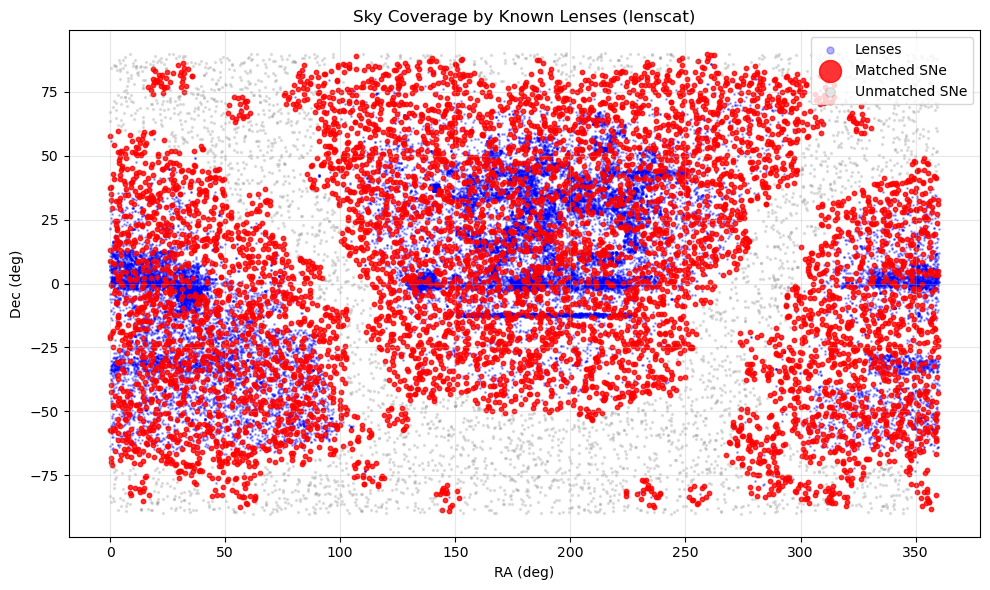

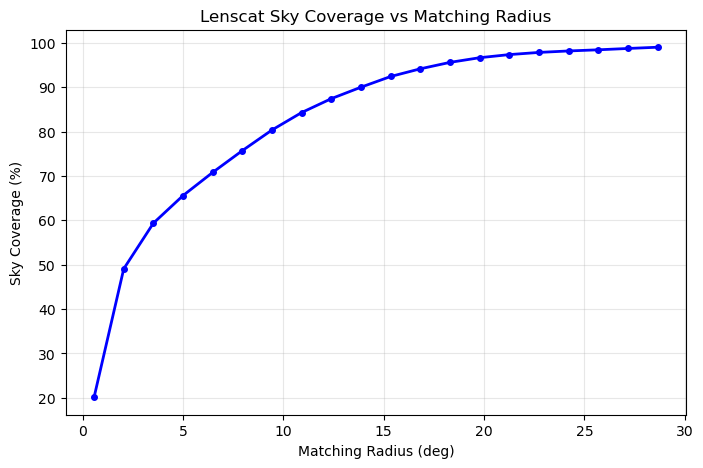


✅ Analysis complete!


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

# --- 1. Read lenscat data ---
df_lens = pd.read_csv('lenscat_catalog.csv')

# Extract lens coordinates (RA, Dec), convert to radians
ra_lens = np.radians(df_lens['RA [deg]'])
dec_lens = np.radians(df_lens['DEC [deg]'])
coords_lens = np.column_stack((ra_lens, dec_lens))

# --- 2. Generate mock supernovae (uniformly distributed across the sky) ---
np.random.seed(42)
n_sne = 10000
ra_sne = np.random.uniform(0, 2*np.pi, n_sne)
dec_sne = np.random.uniform(-np.pi/2, np.pi/2, n_sne)
coords_sne = np.column_stack((ra_sne, dec_sne))

# --- 3. Use KDTree for fast neighbor search ---
tree = cKDTree(coords_lens)

# Define matching radius (angular distance): 0.1 rad ≈ 5.7 deg
# This is a generous radius; actual lens coverage is much smaller
search_radius = 0.1  # radians

# For each mock SN, find the nearest lens
distances, indices = tree.query(coords_sne, distance_upper_bound=search_radius)

# Count how many SNe are matched
matched = distances < search_radius
n_matched = np.sum(matched)
coverage_ratio = n_matched / n_sne * 100

print("="*60)
print("LENSCAT SKY COVERAGE ESTIMATE")
print("="*60)
print(f"Total mock SNe: {n_sne}")
print(f"SNe matched to lenses: {n_matched}")
print(f"Coverage (matching radius {np.degrees(search_radius):.1f}°): {coverage_ratio:.2f}%")
print("="*60)

# --- 4. Visualization: sky distribution of lenses and SNe ---
fig, ax = plt.subplots(figsize=(10, 6))

# Plot all lenses (blue small dots)
ax.scatter(np.degrees(ra_lens), np.degrees(dec_lens), 
           s=1, alpha=0.3, color='blue', label='Lenses')

# Plot matched SNe (red large dots)
matched_sne = coords_sne[matched]
ax.scatter(np.degrees(matched_sne[:, 0]), np.degrees(matched_sne[:, 1]), 
           s=10, alpha=0.8, color='red', label='Matched SNe')

# Plot unmatched SNe (gray small dots)
unmatched_sne = coords_sne[~matched]
ax.scatter(np.degrees(unmatched_sne[:, 0]), np.degrees(unmatched_sne[:, 1]), 
           s=2, alpha=0.2, color='gray', label='Unmatched SNe')

ax.set_xlabel('RA (deg)')
ax.set_ylabel('Dec (deg)')
ax.set_title('Sky Coverage by Known Lenses (lenscat)')
ax.legend(markerscale=5)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('lenscat_sky_coverage.png', dpi=150)
plt.show()

# --- 5. Analyze coverage as a function of matching radius ---
radii = np.linspace(0.01, 0.5, 20)
coverage_ratios = []

for r in radii:
    distances, _ = tree.query(coords_sne, distance_upper_bound=r)
    matched = distances < r
    coverage_ratios.append(np.mean(matched) * 100)

plt.figure(figsize=(8, 5))
plt.plot(np.degrees(radii), coverage_ratios, 'b-o', linewidth=2, markersize=4)
plt.xlabel('Matching Radius (deg)')
plt.ylabel('Sky Coverage (%)')
plt.title('Lenscat Sky Coverage vs Matching Radius')
plt.grid(alpha=0.3)
plt.savefig('lenscat_coverage_vs_radius.png', dpi=150)
plt.show()

print("\n✅ Analysis complete!")

In [21]:
import pandas as pd

# 定义完整数据（包含坐标）
data = {
    'name': ['SN_H0pe', 'SN_Refsdal', 'iPTF16geu', 'SN_Zwicky', 'PS1-10afx'],
    'redshift': [1.783, 1.49, 0.409, 0.3544, 1.3883],
    'magnification': [8.23, 15.0, 52.0, 24.3, 30.8],
    'time_delay_days': [110, 365, 1.46, 0.5, None],
    'reference': ['2403.18902v2', '1512.04654v2', '1611.00014v2', '2211.00656v2', '1302.2785v2'],
    'ra': [171.815, 177.3962, 316.0661, 53.1902, 332.8507],
    'dec': [42.4258, 22.4030, -6.3401, -27.7401, 0.1621]
}

# 转换为DataFrame
df_gisne = pd.DataFrame(data)

# 保存为CSV文件
df_gisne.to_csv('gISNe_sample.csv', index=False)

print("✅ CSV 文件已成功创建（包含坐标）！")
print("\n数据预览：")
print(df_gisne)
print(f"\n共 {len(df_gisne)} 条记录，已保存至 gISNe_sample.csv")

✅ CSV 文件已成功创建（包含坐标）！

数据预览：
         name  redshift  magnification  time_delay_days     reference  \
0     SN_H0pe    1.7830           8.23           110.00  2403.18902v2   
1  SN_Refsdal    1.4900          15.00           365.00  1512.04654v2   
2   iPTF16geu    0.4090          52.00             1.46  1611.00014v2   
3   SN_Zwicky    0.3544          24.30             0.50  2211.00656v2   
4   PS1-10afx    1.3883          30.80              NaN   1302.2785v2   

         ra      dec  
0  171.8150  42.4258  
1  177.3962  22.4030  
2  316.0661  -6.3401  
3   53.1902 -27.7401  
4  332.8507   0.1621  

共 5 条记录，已保存至 gISNe_sample.csv


GRAVITATIONAL LENSING DETECTION ENHANCEMENT
Limiting magnitude: 20.5
Total sample size: 5
------------------------------------------------------------
Detected without lensing: 0
Detected with lensing: 2
Enhancement factor: infx (if n_no_lens>0)


/var/folders/ck/55c7gwgn7fbbqyhwqvxjm8p40000gn/T/ipykernel_4662/1509044181.py:58: RuntimeWarning:

divide by zero encountered in scalar divide



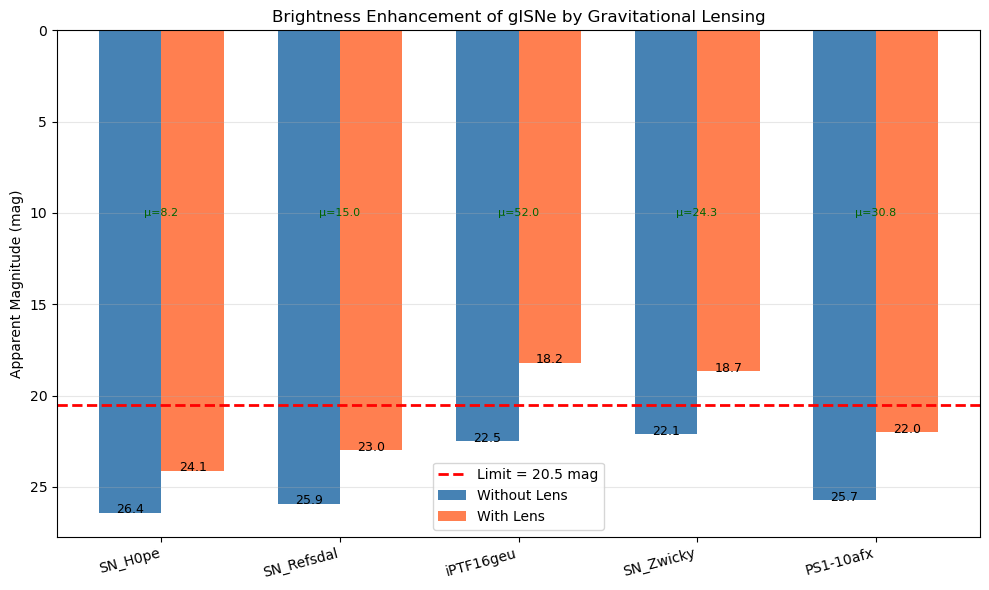


📊 Detailed data table:
         name  redshift  magnification  m_no_lens   m_lensed  \
0     SN_H0pe    1.7830           8.23  26.401312  24.112812   
1  SN_Refsdal    1.4900          15.00  25.921124  22.980895   
2   iPTF16geu    0.4090          52.00  22.491542  18.201534   
3   SN_Zwicky    0.3544          24.30  22.125699  18.661683   
4   PS1-10afx    1.3883          30.80  25.731506  22.010129   

   detected_no_lens  detected_lensed  
0             False            False  
1             False            False  
2             False             True  
3             False             True  
4             False            False  


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Read data ---
df = pd.read_csv('gISNe_sample.csv')

# --- 2. Define constants ---
# Absolute magnitude of SN Ia (peak)
M_B = -19.25  # standard value

# --- 3. Calculate expected apparent magnitude without lensing (m_no_lens) ---
# Distance modulus formula: m = M + 5*log10(D_L / 10pc)
# For accuracy, we use astropy
from astropy.cosmology import FlatLambdaCDM
from astropy import units as u

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

def luminosity_distance_redshift(z):
    """Compute luminosity distance (in Mpc)"""
    return cosmo.luminosity_distance(z).value

# Compute expected magnitude for each SN
m_no_lens = []
for z in df['redshift']:
    d_L = luminosity_distance_redshift(z)
    # Distance modulus: 5*log10(d_L / 10pc)
    # 1 Mpc = 10^6 pc, so 10pc = 10^-5 Mpc
    dist_mod = 5 * np.log10(d_L / 1e-5)
    m_no_lens.append(M_B + dist_mod)

df['m_no_lens'] = m_no_lens

# --- 4. Calculate observed magnitude with lensing (m_lensed) ---
# Formula: m_lensed = m_no_lens - 2.5*log10(μ)
df['m_lensed'] = df['m_no_lens'] - 2.5 * np.log10(df['magnification'])

# --- 5. Calculate detection rate enhancement ---
# Assume a limiting magnitude (e.g., ZTF ~20.5 mag)
limiting_mag = 20.5

df['detected_no_lens'] = df['m_no_lens'] < limiting_mag
df['detected_lensed'] = df['m_lensed'] < limiting_mag

# Statistics (small sample, but demonstrates the concept)
n_no_lens = df['detected_no_lens'].sum()
n_lensed = df['detected_lensed'].sum()

print("="*60)
print("GRAVITATIONAL LENSING DETECTION ENHANCEMENT")
print("="*60)
print(f"Limiting magnitude: {limiting_mag}")
print(f"Total sample size: {len(df)}")
print("-"*60)
print(f"Detected without lensing: {n_no_lens}")
print(f"Detected with lensing: {n_lensed}")
print(f"Enhancement factor: {n_lensed / n_no_lens:.1f}x (if n_no_lens>0)")
print("="*60)

# --- 6. Visualization: brightness comparison ---
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(df))
width = 0.35

# Bar chart: without lens vs with lens
bars1 = ax.bar(x - width/2, df['m_no_lens'], width, label='Without Lens', color='steelblue')
bars2 = ax.bar(x + width/2, df['m_lensed'], width, label='With Lens', color='coral')

# Mark the detection limit
ax.axhline(limiting_mag, color='red', linestyle='--', linewidth=2, label=f'Limit = {limiting_mag} mag')

# Add value labels
for i, (no_lens, lensed) in enumerate(zip(df['m_no_lens'], df['m_lensed'])):
    ax.text(i - width/2, no_lens + 0.2, f'{no_lens:.1f}', ha='center', va='bottom', fontsize=9)
    ax.text(i + width/2, lensed + 0.2, f'{lensed:.1f}', ha='center', va='bottom', fontsize=9)

# Annotate magnification factors
for i, mag in enumerate(df['magnification']):
    ax.text(i, 10, f'μ={mag:.1f}', ha='center', va='center', fontsize=8, color='darkgreen')

ax.set_xticks(x)
ax.set_xticklabels(df['name'], rotation=15, ha='right')
ax.set_ylabel('Apparent Magnitude (mag)')
ax.set_title('Brightness Enhancement of gISNe by Gravitational Lensing')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.invert_yaxis()  # Astronomical convention: brightness increases downward

plt.tight_layout()
plt.savefig('gisne_brightness_enhancement.png', dpi=150)
plt.show()

# --- 7. Print detailed data table ---
print("\n📊 Detailed data table:")
print(df[['name', 'redshift', 'magnification', 'm_no_lens', 'm_lensed', 'detected_no_lens', 'detected_lensed']])

lenscat total records: 32838
Column names: ['name', 'RA [deg]', 'DEC [deg]', 'zlens', 'type', 'grading', 'ref']
           name   RA [deg]  DEC [deg]     zlens    type    grading  \
0    J0011-0845   2.834350    -8.7643         -  galaxy  confident   
1    J0013+5119   3.348077    51.3183         -  galaxy  confident   
2  PSJ0028+0631   7.093690     6.5317         -  galaxy  confident   
3  PSJ0030-1525   7.563600   -15.4177  measured  galaxy  confident   
4    J0047+2514  11.946594    25.2411         -  galaxy  confident   

                                                 ref  
0  https://research.ast.cam.ac.uk/lensedquasars/i...  
1  https://research.ast.cam.ac.uk/lensedquasars/i...  
2  https://research.ast.cam.ac.uk/lensedquasars/i...  
3  https://research.ast.cam.ac.uk/lensedquasars/i...  
4  https://research.ast.cam.ac.uk/lensedquasars/i...  
Valid redshift records: 13941


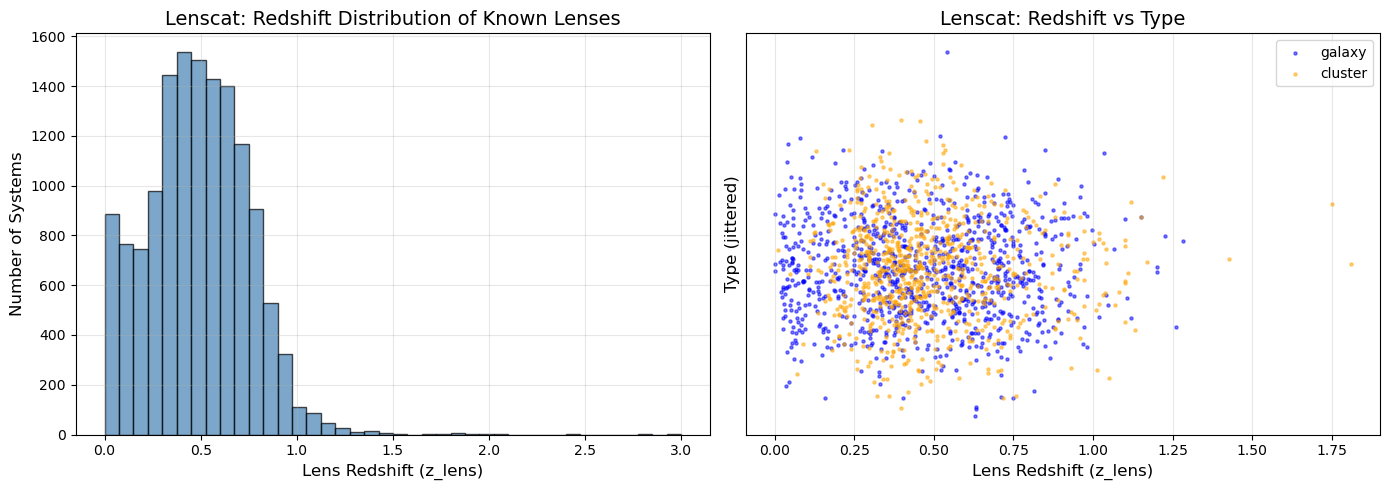


LENSCAT STATISTICAL SUMMARY
Total records: 32838
Valid redshift records: 13941
Redshift range: 0.000 - 3.000
Redshift median: 0.480

Lens type distribution:
type
galaxy     13111
cluster      830
Name: count, dtype: int64


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Read lenscat data ---
df_lens = pd.read_csv('lenscat_catalog.csv')

# Inspect the data
print(f"lenscat total records: {len(df_lens)}")
print(f"Column names: {df_lens.columns.tolist()}")
print(df_lens.head())

# --- 2. Filter valid redshifts ---
# Exclude 'not measured' or '-' cases
df_lens_valid = df_lens[df_lens['zlens'] != 'not measured'].copy()
df_lens_valid['zlens'] = pd.to_numeric(df_lens_valid['zlens'], errors='coerce')
df_lens_valid = df_lens_valid.dropna(subset=['zlens'])

print(f"Valid redshift records: {len(df_lens_valid)}")

# --- 3. Plot redshift distribution ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Redshift histogram
ax = axes[0]
ax.hist(df_lens_valid['zlens'], bins=40, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Lens Redshift (z_lens)', fontsize=12)
ax.set_ylabel('Number of Systems', fontsize=12)
ax.set_title('Lenscat: Redshift Distribution of Known Lenses', fontsize=14)
ax.grid(alpha=0.3)

# Right: Redshift vs Type (scatter plot)
ax = axes[1]
types = df_lens_valid['type'].unique()
colors = {'galaxy': 'blue', 'cluster': 'orange', 'group': 'green'}
for t in types:
    subset = df_lens_valid[df_lens_valid['type'] == t]
    # Random sampling to avoid overplotting
    sample = subset.sample(min(1000, len(subset)), random_state=42)
    ax.scatter(sample['zlens'], np.random.normal(0, 0.1, len(sample)), 
               s=5, alpha=0.5, label=t, color=colors.get(t, 'gray'))

ax.set_xlabel('Lens Redshift (z_lens)', fontsize=12)
ax.set_ylabel('Type (jittered)', fontsize=12)
ax.set_title('Lenscat: Redshift vs Type', fontsize=14)
ax.set_yticks([])
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('lenscat_distribution.png', dpi=150)
plt.show()

# --- 4. Print statistical summary ---
print("\n" + "="*50)
print("LENSCAT STATISTICAL SUMMARY")
print("="*50)
print(f"Total records: {len(df_lens)}")
print(f"Valid redshift records: {len(df_lens_valid)}")
print(f"Redshift range: {df_lens_valid['zlens'].min():.3f} - {df_lens_valid['zlens'].max():.3f}")
print(f"Redshift median: {df_lens_valid['zlens'].median():.3f}")
print("\nLens type distribution:")
print(df_lens_valid['type'].value_counts())
print("="*50)

lenscat valid data points: 13941
Real gISNe count: 5


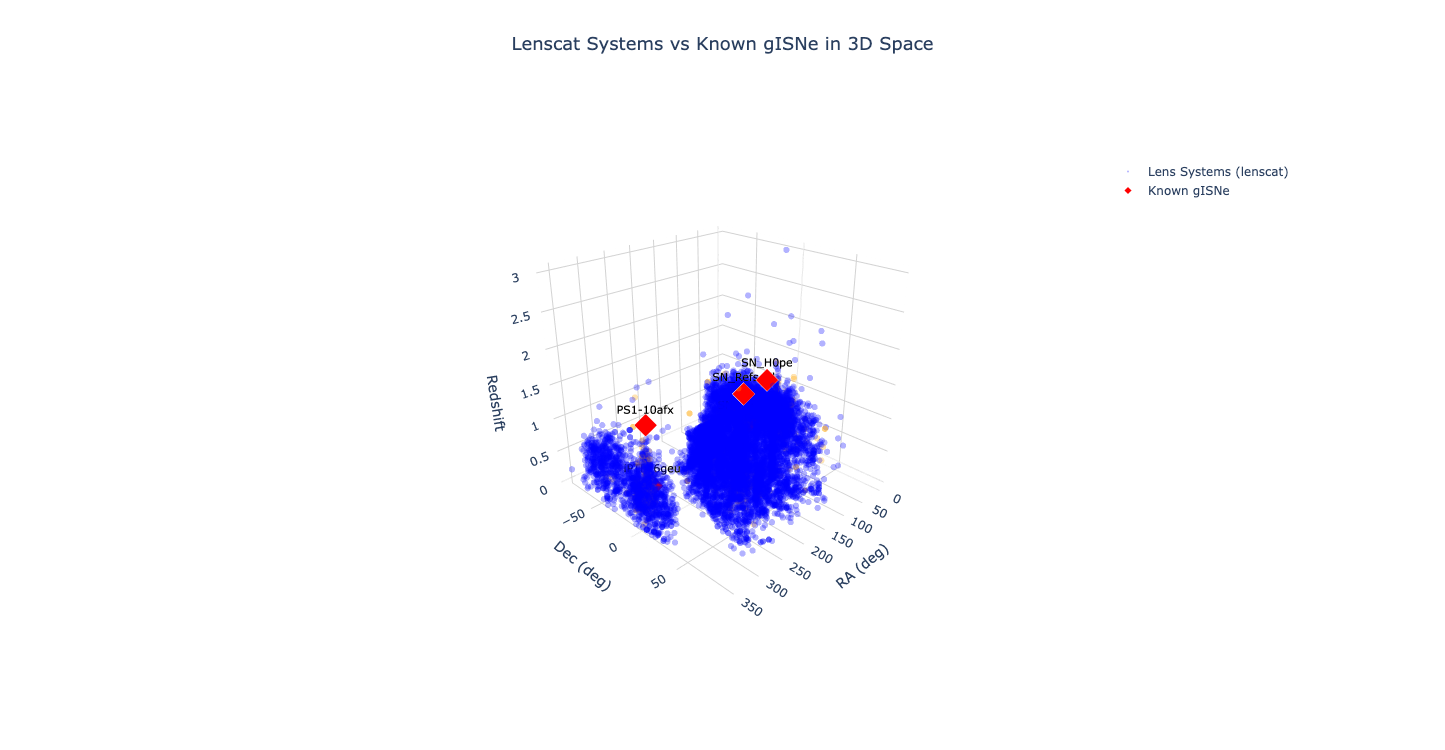

In [27]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

# --- 1. Read lenscat data ---
df_lens = pd.read_csv('lenscat_catalog.csv')

# Filter valid redshifts
df_lens_valid = df_lens[df_lens['zlens'] != 'not measured'].copy()
df_lens_valid['zlens'] = pd.to_numeric(df_lens_valid['zlens'], errors='coerce')
df_lens_valid = df_lens_valid.dropna(subset=['zlens'])

ra_lens = df_lens_valid['RA [deg]'].values
dec_lens = df_lens_valid['DEC [deg]'].values
z_lens = df_lens_valid['zlens'].values

# Assign colors by lens type
type_colors = {'galaxy': 'blue', 'cluster': 'orange', 'group': 'green'}
colors_lens = [type_colors.get(t, 'gray') for t in df_lens_valid['type'].values]

print(f"lenscat valid data points: {len(ra_lens)}")

# --- 2. Read real gISNe data ---
df_real = pd.read_csv('gISNe_sample.csv')

ra_real = df_real['ra'].values
dec_real = df_real['dec'].values
z_real = df_real['redshift'].values
mag_real = df_real['magnification'].values
names_real = df_real['name'].values

print(f"Real gISNe count: {len(df_real)}")

# --- 3. Create 3D scatter plot ---
fig = go.Figure()

# 3.1 Lens systems (background points)
fig.add_trace(go.Scatter3d(
    x=ra_lens,
    y=dec_lens,
    z=z_lens,
    mode='markers',
    marker=dict(
        size=2,
        color=colors_lens,
        opacity=0.3
    ),
    name='Lens Systems (lenscat)',
    hoverinfo='skip'
))

# 3.2 Real gISNe (highlighted foreground points)
fig.add_trace(go.Scatter3d(
    x=ra_real,
    y=dec_real,
    z=z_real,
    mode='markers+text',
    marker=dict(
        size=7,
        color='red',
        symbol='diamond',
        line=dict(color='white', width=1.5)
    ),
    text=names_real,
    textposition='top center',
    textfont=dict(color='black', size=11),
    name='Known gISNe',
    hovertemplate='<b>%{text}</b><br>z=%{z:.3f}<br>μ=%{customdata:.1f}<extra></extra>',
    customdata=mag_real
))

# --- 4. Set layout ---
fig.update_layout(
    title=dict(
        text='Lenscat Systems vs Known gISNe in 3D Space',
        font=dict(size=18),
        x=0.5
    ),
    scene=dict(
        xaxis=dict(title='RA (deg)', backgroundcolor='white', gridcolor='lightgray'),
        yaxis=dict(title='Dec (deg)', backgroundcolor='white', gridcolor='lightgray'),
        zaxis=dict(title='Redshift', backgroundcolor='white', gridcolor='lightgray'),
        camera=dict(
            eye=dict(x=1.8, y=1.8, z=1.2),
            center=dict(x=0, y=0, z=0)
        )
    ),
    paper_bgcolor='white',
    width=1000,
    height=750,
    legend=dict(
        x=0.8,
        y=0.9,
        bgcolor='rgba(255,255,255,0.8)',
        font=dict(size=12)
    )
)

fig.show()